(solid-mechanics:small-displacements:plates-shells:kirchhoff-analytical)=
# Analytic solution of bending of a hinged Kirchhoff plate



In [1]:
# --- Navier Analytical Solution for a Simply Supported Kirchhoff Plate (2D Contour) ---
# Domain: [0, Lx] x [0, Ly] under a uniform transverse load q0[cite: 2, 3].

import numpy as np
import matplotlib.pyplot as plt

# 1. Plate & Material Parameters
Lx = 2.0        # Plate length along x-axis [m]
Ly = 1.5        # Plate length along y-axis [m]
h = 0.012       # Plate thickness [m]
E = 210e9       # Young's modulus (Steel) [Pa]
nu = 0.3        # Poisson's ratio [-]

# Flexural rigidity of the plate: D = E*h^3 / (12*(1 - nu^2))
D = (E * h**3) / (12.0 * (1.0 - nu**2))

# 2. Loading & Series Convergence Parameters
q0 = 5000.0     # Uniform distributed load intensity [N/m^2]
N_terms = 15     # Number of odd half-wave terms (n_x, n_y = 1, 3, 5, ..., 2*N_terms - 1)

# 3. Spatial Discretization Grid
nx_pts, ny_pts = 150, 150
x = np.linspace(0, Lx, nx_pts)
y = np.linspace(0, Ly, ny_pts)
X, Y = np.meshgrid(x, y)


## Out-of-plane displacement $w(x,y)$ and small rotations $\boldsymbol\theta(x,y)$

Out-of-plane displacement is written as the Fourier series

$$w(x,y) = \sum_{m,n=1, \, \text{odd}}^{+\infty} a_{mn} \sin \left( \frac{m \pi x}{L_x} \right) \sin \left(  \frac{n \pi y}{L_y} \right) \ .$$

Small rotations reads $\boldsymbol \theta = - \hat{\mathbf{z}} \times \nabla w$ - the inverse relation is $\nabla w = \hat{\mathbf{z}} \times \boldsymbol\theta$ - or in Cartesian components

$$\left\{ \begin{aligned}
  \theta_x & = w_{/y} \\
  \theta_y & = -w_{/x} \ .
\end{aligned} \right.$$

Using the analytical solution,

$$\left\{ \begin{aligned}
  \theta_x & = \sum_{m,n=1, \, \text{odd}}^{+\infty} a_{mn} \left( \frac{n \pi}{L_y} \right) \sin \left( \frac{m \pi x}{L_x} \right) \cos \left(  \frac{m \pi x}{L_x} \right) \\
  \theta_y & = - \sum_{m,n=1, \, \text{odd}}^{+\infty} a_{mn} \left( \frac{m \pi}{L_x} \right) \cos \left( \frac{m \pi x}{L_x} \right) \sin \left(  \frac{m \pi x}{L_x} \right) \ .
\end{aligned} \right.$$








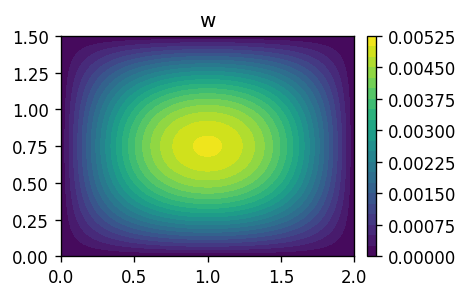

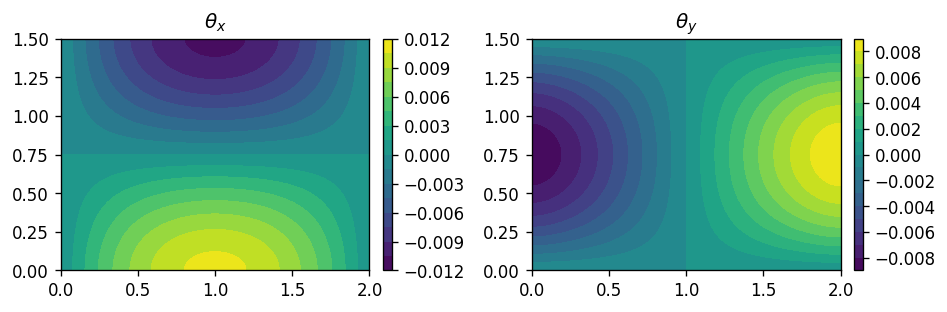

In [2]:
# 4. Evaluation of the Navier Double Sine Series
w = np.zeros_like(X)         # Out-of-plane displacement
theta_x = np.zeros_like(X)   # Rotations
theta_y = np.zeros_like(X)   #
theta_x_x = np.zeros_like(X)
theta_x_y = np.zeros_like(X)
theta_y_x = np.zeros_like(X)
theta_y_y = np.zeros_like(X)
del_w_x = np.zeros_like(X)
del_w_y = np.zeros_like(X)
del_w = np.zeros_like(X)
del_del_w = np.zeros_like(X)

for i in range(N_terms):
    nx = 2 * i + 1  # Navier solution symmetry ensures even terms vanish for uniform load[cite: 3]
    for j in range(N_terms):
        ny = 2 * j + 1
        
        # Fourier coefficient for uniform load expansion f_{nx, ny}[cite: 3]
        f_mn = (16.0 * q0) / (np.pi**2 * nx * ny)
        
        # Biharmonic operator denominator eigenvalue factor[cite: 2, 3]
        denominator = D * np.pi**4 * ((nx / Lx)**2 + (ny / Ly)**2)**2
        
        # Modal amplitude a_{nx, ny}
        a_mn = f_mn / denominator
        
        # Accumulate series contribution
        w += a_mn * np.sin(nx * np.pi * X / Lx) * np.sin(ny * np.pi * Y / Ly)
        theta_x += a_mn * (ny*np.pi/Ly) * np.sin(nx * np.pi * X / Lx) * np.cos(ny * np.pi * Y / Ly)
        theta_y -= a_mn * (nx*np.pi/Lx) * np.cos(nx * np.pi * X / Lx) * np.sin(ny * np.pi * Y / Ly)
        
        theta_x_x += a_mn * (ny*np.pi/Ly) * (nx*np.pi/Lx) * np.cos(nx * np.pi * X / Lx) * np.cos(ny * np.pi * Y / Ly)
        theta_x_y -= a_mn * (nx*np.pi/Lx)**2              * np.sin(nx * np.pi * X / Lx) * np.sin(ny * np.pi * Y / Ly)
        theta_y_x += a_mn * (ny*np.pi/Lx)**2              * np.sin(nx * np.pi * X / Lx) * np.sin(ny * np.pi * Y / Ly)
        theta_y_y -= a_mn * (nx*np.pi/Lx) * (nx*np.pi/Ly) * np.cos(nx * np.pi * X / Lx) * np.cos(ny * np.pi * Y / Ly)

        del_w_x -= a_mn * ( (nx*np.pi/Lx)**2 + (ny*np.pi/Ly)**2  ) * (nx*np.pi/Lx) * np.cos(nx * np.pi * X / Lx) * np.sin(ny * np.pi * Y / Ly)
        del_w_y -= a_mn * ( (nx*np.pi/Lx)**2 + (ny*np.pi/Ly)**2  ) * (ny*np.pi/Ly) * np.sin(nx * np.pi * X / Lx) * np.cos(ny * np.pi * Y / Ly)

        del_w -= a_mn * ( (nx*np.pi/Lx)**2 + (ny*np.pi/Ly)**2  ) * np.sin(nx * np.pi * X / Lx) * np.sin(ny * np.pi * Y / Ly)
        
        del_del_w += a_mn * ( (nx*np.pi/Lx)**2 + (ny*np.pi/Ly)**2  )**2 * np.sin(nx * np.pi * X / Lx) * np.sin(ny * np.pi * Y / Ly)
        
# 5. 2D Contour Visualization

# Convert deflection to millimeters for readability and create filled contours
contour_levels = 20

fig, ax = plt.subplots(1,1, figsize=(4, 3), dpi=120)
cf = ax.contourf(X, Y, w, levels=contour_levels, cmap='viridis')
cbar = fig.colorbar(cf, ax=ax, fraction=0.028, pad=0.04, aspect=25)

ax.set_title('w')
ax.set_aspect('equal', adjustable='box')

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1,2, figsize=(8, 3), dpi=120)
cf = ax[0].contourf(X, Y, theta_x, levels=contour_levels, cmap='viridis')
cbar = fig.colorbar(cf, ax=ax[0], fraction=0.028, pad=0.04, aspect=25)
cf = ax[1].contourf(X, Y, theta_y, levels=contour_levels, cmap='viridis')
cbar = fig.colorbar(cf, ax=ax[1], fraction=0.028, pad=0.04, aspect=25)

# Add subtle contour lines for enhanced clarity
# cbar.set_label('Transverse Deflection $w$', labelpad=10)

titles = [ r'${\theta_x}$', r'${\theta_y}$' ]
for isub in np.arange(len(titles)):
    ax[isub].set_title(titles[isub])
    ax[isub].set_aspect('equal', adjustable='box')

# ax[0].set_title(f'Navier Solution: Plate Deflection ($L_x$={Lx}, $L_y$={Ly})', fontsize=12, pad=12)
# ax.set_xlabel('$x$', labelpad=8)
# ax.set_ylabel('$y$', labelpad=8)

plt.tight_layout()
plt.show()


## Internal moment and force

Internal moment tensor

$$\mathbb{M} = D \nabla \boldsymbol\theta - m D \nabla^T \boldsymbol\theta$$

Internal transverse force vector

$$\mathbf{F} =  - D \nabla \Delta w = D \hat{\mathbf{z}} \times \Delta \boldsymbol\theta \ .$$

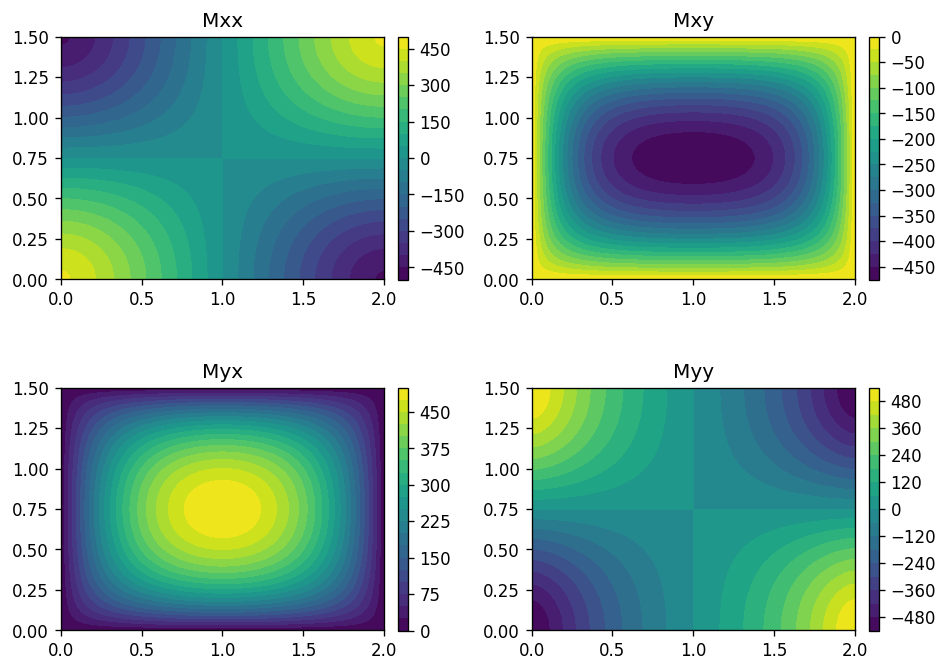

In [3]:
# 5. 2D Contour Visualization
fig, ax = plt.subplots(2,2, figsize=(8,6), dpi=120)

# Convert deflection to millimeters for readability and create filled contours
contour_levels = 20
cf = ax[0,0].contourf(X, Y, D*(1-nu)*theta_x_x, levels=contour_levels, cmap='viridis')
cbar = fig.colorbar(cf, ax=ax[0,0], fraction=0.028, pad=0.04, aspect=25)
cf = ax[0,1].contourf(X, Y, D*(theta_x_y-nu*theta_y_x), levels=contour_levels, cmap='viridis')
cbar = fig.colorbar(cf, ax=ax[0,1], fraction=0.028, pad=0.04, aspect=25)
cf = ax[1,0].contourf(X, Y, D*(theta_y_x-nu*theta_x_y), levels=contour_levels, cmap='viridis')
cbar = fig.colorbar(cf, ax=ax[1,0], fraction=0.028, pad=0.04, aspect=25)
cf = ax[1,1].contourf(X, Y, D*(1-nu)*theta_y_y, levels=contour_levels, cmap='viridis')
cbar = fig.colorbar(cf, ax=ax[1,1], fraction=0.028, pad=0.04, aspect=25)

# Add subtle contour lines for enhanced clarity
"""
cbar.set_label('Transverse Deflection $w$', labelpad=10)
"""
titles = np.array([  [ "Mxx", "Mxy" ], [ "Myx", "Myy"] ])
for isub_x in np.arange(2):
    for isub_y in np.arange(2):
        ax[isub_x, isub_y].set_title(titles[isub_x, isub_y])
        ax[isub_x, isub_y].set_aspect('equal', adjustable='box')

# ax[0].set_title(f'Navier Solution: Plate Deflection ($L_x$={Lx}, $L_y$={Ly})', fontsize=12, pad=12)
# ax.set_xlabel('$x$', labelpad=8)
# ax.set_ylabel('$y$', labelpad=8)

plt.tight_layout()
plt.show()

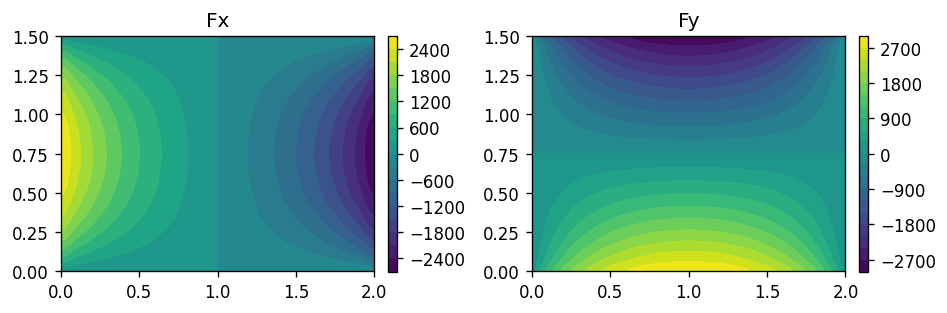

In [4]:
# 5. 2D Contour Visualization
fig, ax = plt.subplots(1,2, figsize=(8,3), dpi=120)

# Convert deflection to millimeters for readability and create filled contours
contour_levels = 20
cf = ax[0].contourf(X, Y, -D*del_w_x, levels=contour_levels, cmap='viridis')
cbar = fig.colorbar(cf, ax=ax[0], fraction=0.028, pad=0.04, aspect=25)
cf = ax[1].contourf(X, Y, -D*del_w_y, levels=contour_levels, cmap='viridis')
cbar = fig.colorbar(cf, ax=ax[1], fraction=0.028, pad=0.04, aspect=25)

# Add subtle contour lines for enhanced clarity
"""
cbar.set_label('Transverse Deflection $w$', labelpad=10)
"""
titles = np.array([ "Fx", "Fy" ])
for isub_x in np.arange(2):
        ax[isub_x].set_title(titles[isub_x])
        ax[isub_x].set_aspect('equal', adjustable='box')

# ax[0].set_title(f'Navier Solution: Plate Deflection ($L_x$={Lx}, $L_y$={Ly})', fontsize=12, pad=12)
# ax.set_xlabel('$x$', labelpad=8)
# ax.set_ylabel('$y$', labelpad=8)

plt.tight_layout()
plt.show()


## Laplacian and double Laplacian of the out-of-plane displacement $w(x,y)$

Here, the double Laplacian is the Fourier series approximation of the external distributed load.

...



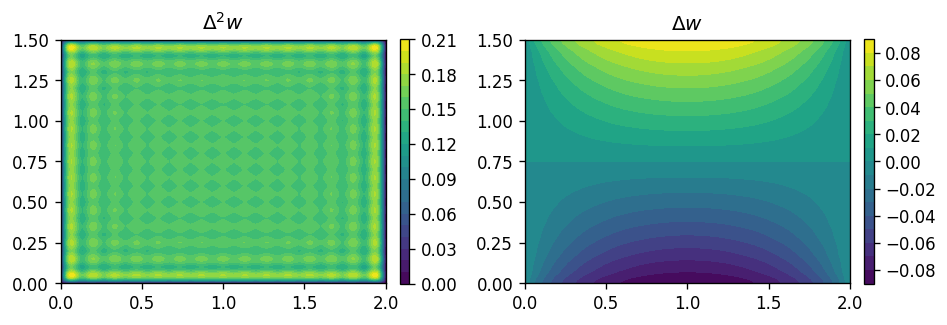

Avg(del_del_w)  : 0.14434850109505598
Uniform load, q0: 5000.0
Stiffness, D    : 33230.769230769234
Avg(del_del_w) * D:  4796.811728697246


In [5]:
# 5. 2D Contour Visualization
fig, ax = plt.subplots(1,2, figsize=(8,3), dpi=120)

# Convert deflection to millimeters for readability and create filled contours
contour_levels = 20
cf = ax[0].contourf(X, Y, del_del_w, levels=contour_levels, cmap='viridis')
cbar = fig.colorbar(cf, ax=ax[0], fraction=0.028, pad=0.04, aspect=25)
cf = ax[1].contourf(X, Y, del_w_y, levels=contour_levels, cmap='viridis')
cbar = fig.colorbar(cf, ax=ax[1], fraction=0.028, pad=0.04, aspect=25)

# Add subtle contour lines for enhanced clarity
"""
cbar.set_label('Transverse Deflection $w$', labelpad=10)
"""
titles = np.array([ r"$\Delta^2 w$", r"$\Delta w$" ])
for isub_x in np.arange(2):
        ax[isub_x].set_title(titles[isub_x])
        ax[isub_x].set_aspect('equal', adjustable='box')

# ax[0].set_title(f'Navier Solution: Plate Deflection ($L_x$={Lx}, $L_y$={Ly})', fontsize=12, pad=12)
# ax.set_xlabel('$x$', labelpad=8)
# ax.set_ylabel('$y$', labelpad=8)

plt.tight_layout()
plt.show()

print("Avg(del_del_w)  :", np.mean(del_del_w))
print("Uniform load, q0:", q0)
print("Stiffness, D    :", D)

print("Avg(del_del_w) * D: ", np.mean(del_del_w) * D) 

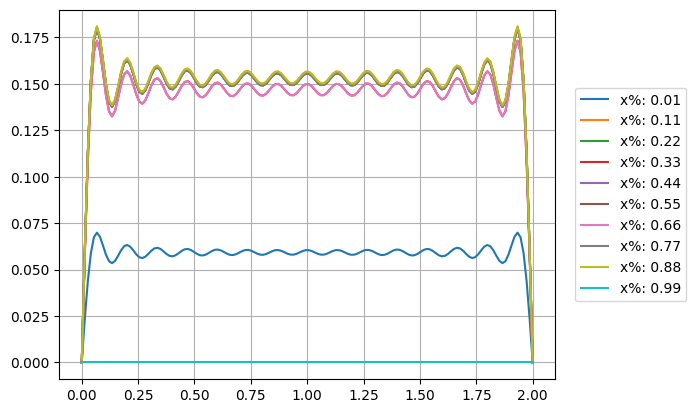

In [6]:
fig = plt.figure()

for ix_pt in np.linspace(1, nx_pts-1, 10):
    i_x = int(np.floor(ix_pt))
    plt.plot(x, del_del_w[i_x,:], label=f"x%: {i_x/nx_pts:.2f}")

plt.legend(bbox_to_anchor=(1.04, 0.5), loc="center left", borderaxespad=0)
plt.grid()
plt.show()
# plt.plot(del_del_w[75,:])